In [10]:
from google.colab import files

uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


Dataset loaded successfully!

Dataset shape: (200, 5)

First five rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0

Feature scaling completed!


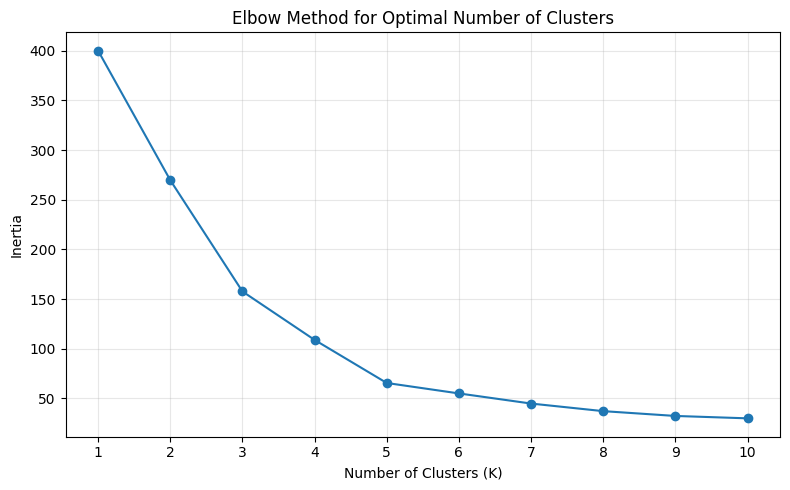


K-Means clustering completed!
Number of clusters: 5
Silhouette Score: 0.555


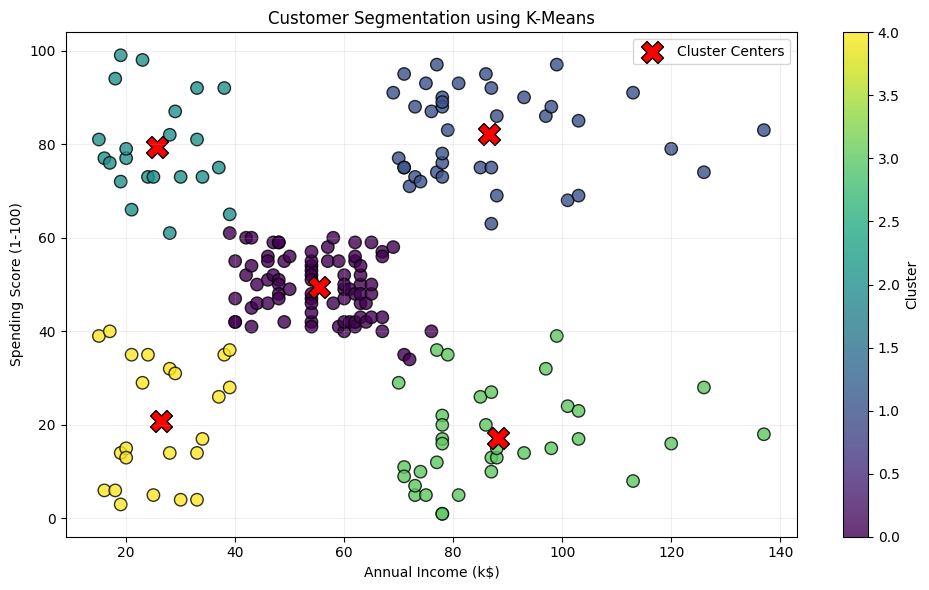


Customer Cluster Summary:
         Average_Annual_Income  Average_Spending_Score  Number_of_Customers
Cluster                                                                    
0                        55.30                   49.52                   81
1                        86.54                   82.13                   39
2                        25.73                   79.36                   22
3                        88.20                   17.11                   35
4                        26.30                   20.91                   23

Customer assignments:
 CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
          1                  15                      39        4
          2                  15                      81        2
          3                  16                       6        4
          4                  16                      77        2
          5                  17                      40        4
          6                 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Task 02 completed successfully!


In [11]:

# ============================================================
# PRODIGY INFOTECH - MACHINE LEARNING INTERNSHIP
# TASK 02: CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING
# Dataset: Mall Customer Segmentation Data (Kaggle)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# STEP 1: Load the dataset
df = pd.read_csv("Mall_Customers.csv")

print("Dataset loaded successfully!")
print("\nDataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

# STEP 2: Explore and clean the dataset
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# STEP 3: Select features for clustering
# Income and spending score are useful for customer segmentation.
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

df = df.dropna(subset=features).copy()
X = df[features]

# STEP 4: Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nFeature scaling completed!")

# STEP 5: Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("elbow_method.png", dpi=300)
plt.show()

# STEP 6: Apply K-Means clustering
# Five clusters are a common starting point for this dataset.
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nK-Means clustering completed!")
print("Number of clusters:", df["Cluster"].nunique())

# STEP 7: Evaluate the clustering
score = silhouette_score(X_scaled, df["Cluster"])
print("Silhouette Score:", round(score, 3))

# STEP 8: Visualize the customer segments
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis",
    s=80,
    edgecolors="black",
    alpha=0.8
)

# Plot cluster centers in the original feature scale
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolors="black",
    label="Cluster Centers"
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.colorbar(scatter, label="Cluster")
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig("customer_segmentation.png", dpi=300)
plt.show()

# STEP 9: Analyze the clusters
summary = df.groupby("Cluster").agg(
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean"),
    Number_of_Customers=("CustomerID", "count")
)

print("\nCustomer Cluster Summary:")
print(summary.round(2))

# STEP 10: Display customer assignments
print("\nCustomer assignments:")
print(
    df[[
        "CustomerID",
        "Annual Income (k$)",
        "Spending Score (1-100)",
        "Cluster"
    ]].head(20).to_string(index=False)
)

# STEP 11: Save the results
df.to_csv("Customer_Segmentation_Results.csv", index=False)
summary.to_csv("Customer_Cluster_Summary.csv")

print("\nAll results saved successfully!")

# STEP 12: Download output files in Google Colab
from google.colab import files

files.download("Customer_Segmentation_Results.csv")
files.download("Customer_Cluster_Summary.csv")
files.download("customer_segmentation.png")
files.download("elbow_method.png")

print("\nTask 02 completed successfully!")
